# Objetivos

1) Construir un modelo de regresión lineal que permita estimar el área que podría verse afectada por un incendio forestal.

2) Determinar cuáles son las variables que más inciden en la magnitud de un incendio.

El conjunto de datos está constituido por registros de incendios que han ocurrido en el pasado y comprende variables sobre el tipo de vegetación, promedio de precipitaciones y el tamaño del área afectada, entre otras. Es importante que revises el diccionario como primer paso para comprender estos datos.

# Actividades a realizar

1. Carga, exploración y visualización de los datos. 

2. Preparación de los datos.

3. Construcción del modelo de regresión lineal.

4. Evaluación del modelo.

5. Interpretación del modelo.

In [4]:
# Librerias
import os
from pathlib import Path

import numpy as np
import pandas as pd
import statistics as stats
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [5]:
# Rutas
BASE_DIR = Path.cwd() # para .py -> Path(__file__).resolve().parent
RUTA_ENTRADAS = BASE_DIR / "Entradas"
RUTA_SALIDAS = BASE_DIR / "Salidas"

# 1) Carga, exploración y visualización

In [6]:
# Listar archivos en ruta entradas
ficheros = list(RUTA_ENTRADAS.glob("*"))
for f in ficheros:
    if "diccionario" in f.name:
        print(f.name)
        diccionario = pd.read_excel(f)
        diccionario = diccionario.apply(lambda x: x.str.replace({"á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u"}) if (x.dtype == "object") or (x.dtype == "str") else x)
    else:
        data = pd.read_excel(f)


datos_proyecto_modulo2_diccionario.xlsx


In [7]:
# imprimir cada variable y su Description VS comprobarel tipo en la data
for i in range(len(diccionario)):
    # En el diccionario
    variable = diccionario.iloc[i, 0]
    descripcion = diccionario.iloc[i, -1]
    tipo = diccionario.iloc[i, 1]
    # en la data
    tipo_data = data[variable].dtype
    # Comparación
    print("Variable:", variable) 
    print("Descripcion:", descripcion)
    print("tipo:", tipo, ". Tipo en data:", tipo_data)
    print("----------")

Variable: area_quemada
Descripcion: Tamaño del fuego (ha)
tipo: numerico . Tipo en data: float64
----------
Variable: clase_incendio
Descripcion: Clase de tamaño de fuego (A-G)
tipo: categorico . Tipo en data: str
----------
Variable: mes_incendio
Descripcion: Mes en el que se descubrio el fuego.
tipo: categorico . Tipo en data: str
----------
Variable: vegetacion
Descripcion: Vegetacion dominante en las zonas.
tipo: categorico . Tipo en data: str
----------
Variable: Prec_pre_30
Descripcion: Precipitacion (en mm) en el lugar del incendio, hasta 30 dias antes.
tipo: numerico . Tipo en data: float64
----------
Variable: Prec_pre_15
Descripcion: Precipitacion (en mm) en el lugar del incendio, hasta 15 dias antes.
tipo: numerico . Tipo en data: float64
----------
Variable: Prec_pre_7
Descripcion: Precipitacion (en mm) en el lugar del incendio hasta 7 dias antes.
tipo: numerico . Tipo en data: float64
----------
Variable: Prec_cont
Descripcion: Precipitacion (en mm) en el lugar del incendi

**Nota:** La lectura automatica lee de forma correcta el tipo de dato.

In [8]:
# Check de nulos
print(data.isnull().sum())

area_quemada      0
clase_incendio    0
mes_incendio      0
vegetacion        0
Prec_pre_30       0
Prec_pre_15       0
Prec_pre_7        0
Prec_cont         0
dtype: int64


In [9]:
# check duplicados
print(data.duplicated().sum())

11365


In [10]:
# Limpieza de duplicados
size_before = data.shape[0]
data = data.drop_duplicates()
size_after = data.shape[0]
print("Tamaño después de eliminar duplicados:", size_after)
print("Se eliminaron", size_before - size_after, "duplicados")

Tamaño después de eliminar duplicados: 26394
Se eliminaron 11365 duplicados


In [11]:
# Datos estadisticos basicos de las variables
# numerica
colNum = data.select_dtypes(include=float).columns
data[list(colNum)].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
area_quemada,26394.0,3174.960529,17917.514785,0.51,1.5,5.0,46.73,538049.0
Prec_pre_30,26394.0,50.797568,152.717610,0.00,0.0,16.6,59.70,13560.8
Prec_pre_15,26394.0,22.813916,77.581773,0.00,0.0,2.8,23.50,2527.0
Prec_pre_7,26394.0,9.545003,43.286655,0.00,0.0,0.0,5.90,1638.0
Prec_cont,26394.0,30.116409,80.864260,0.00,0.0,0.0,28.90,2126.0


In [12]:
colNum# categorica
data.loc[:, ~data.columns.isin(colNum)].describe().transpose()

,count,unique,top,freq
clase_incendio,26394,6,B,15496
mes_incendio,26394,12,Abril,3488
vegetacion,26394,7,Matorral abierto,7816


In [13]:
# Hacerse una idea de la correlación con la variable de salida: area_quemada

# Correlación salida vs variables numéricas
data_num = data[list(colNum)].copy()
correlation = data_num.corr()
correlation["area_quemada"].sort_values(ascending=False)

area_quemada    1.000000
Prec_pre_7     -0.031446
Prec_pre_15    -0.042713
Prec_cont      -0.047977
Prec_pre_30    -0.049403
Name: area_quemada, dtype: float64

In [14]:
data_cat = data.loc[:, ~data.columns.isin(colNum)].copy()
data_cat = data_cat.join(data["area_quemada"])
# Supongamos que clase_incendio A es más peligroso que B y C
tipos_existentes = data_cat["clase_incendio"].unique()
# aprovechando que unique ordena alfabeticamente
regla = {tipo: abs(i-len(tipos_existentes)) for i, tipo in enumerate(tipos_existentes)}
data_cat["clase_incendio"] = data_cat["clase_incendio"].map(regla)

# codificar mes_incendio ... esto no es ordinal. Así que conbiene usar one-hot encoding
data_cat = pd.get_dummies(data_cat, columns=["mes_incendio"])

# codificar vegetacion ... esta variable tampoco es ordinal conbiene usar one-hot encoding
data_cat = pd.get_dummies(data_cat, columns=["vegetacion"])

In [15]:
data_cat

,clase_incendio,area_quemada,mes_incendio_Abril,mes_incendio_Agosto,mes_incendio_Diciembre,mes_incendio_Enero,mes_incendio_Febrero,mes_incendio_Julio,mes_incendio_Junio,mes_incendio_Marzo,...,mes_incendio_Noviembre,mes_incendio_Octubre,mes_incendio_Septiembre,vegetacion_Bosque templado,vegetacion_Bosque tropical perennifolio,vegetacion_Bosque tropical perennifolio secundario,vegetacion_Desierto,vegetacion_Desierto polar_roca,vegetacion_Matorral abierto,vegetacion_Pradera_estepa
0,6,3.0,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,5,60.0,False,False,False,False,True,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,6,1.0,False,False,False,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
3,6,5.2,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,6,1.0,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37754,1,8300.0,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,True,False,False
37755,4,4704.0,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
37756,1,5992.0,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,True
37757,4,4336.0,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False


In [16]:
# Correlación salida vs variables categoricas
correlation_cat = data_cat.corr()
correlation_cat["area_quemada"].sort_values(ascending=False)


area_quemada                                          1.000000
mes_incendio_Junio                                    0.123069
vegetacion_Bosque tropical perennifolio               0.103990
mes_incendio_Julio                                    0.077212
mes_incendio_Agosto                                   0.058951
vegetacion_Pradera_estepa                             0.025393
vegetacion_Bosque templado                            0.017361
vegetacion_Desierto polar_roca                        0.017139
vegetacion_Desierto                                   0.003483
mes_incendio_Mayo                                    -0.001026
mes_incendio_Septiembre                              -0.022969
mes_incendio_Octubre                                 -0.025264
mes_incendio_Diciembre                               -0.029963
mes_incendio_Enero                                   -0.034307
mes_incendio_Noviembre                               -0.036975
mes_incendio_Febrero                                 -0

In [17]:
# junte de las correlaciones y ordenamiento
correlation_all = pd.concat([correlation["area_quemada"], correlation_cat["area_quemada"]])
# Veremos la correlación en valor absoluto para entender de forma simple 
# cuáles variables están más relacionadas con el área quemada
correlation_all.apply(lambda x: abs(x)).sort_values(ascending=False)

area_quemada                                          1.000000
area_quemada                                          1.000000
clase_incendio                                        0.415388
mes_incendio_Junio                                    0.123069
vegetacion_Bosque tropical perennifolio               0.103990
mes_incendio_Julio                                    0.077212
vegetacion_Matorral abierto                           0.076520
mes_incendio_Agosto                                   0.058951
mes_incendio_Marzo                                    0.058158
vegetacion_Bosque tropical perennifolio secundario    0.052205
Prec_pre_30                                           0.049403
Prec_cont                                             0.047977
mes_incendio_Abril                                    0.047931
mes_incendio_Febrero                                  0.043529
Prec_pre_15                                           0.042713
mes_incendio_Noviembre                                0

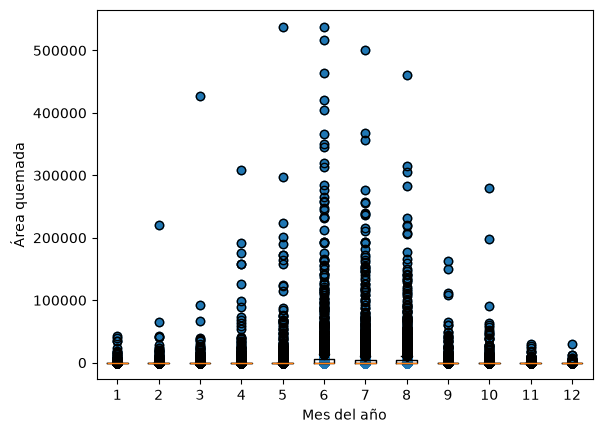

In [26]:
# Grafico: X meses del año, variable Ordinal Enero=1, Febrero=2, ..., Diciembre=12 
# Y variable de salida area_area_quemada
# Codificar
meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
regla_meses = {mes: i+1 for i, mes in enumerate(meses)}
graf = data.copy()
graf["mes_incendio"] = graf["mes_incendio"].map(regla_meses)

plt.scatter(graf["mes_incendio"], graf["area_quemada"])
# hacer boxplot en la misma figura
plt.boxplot([graf.loc[graf["mes_incendio"] == i, "area_quemada"] for i in range(1, 13)])
plt.xlabel("Mes del año")
plt.ylabel("Área quemada")
plt.show()

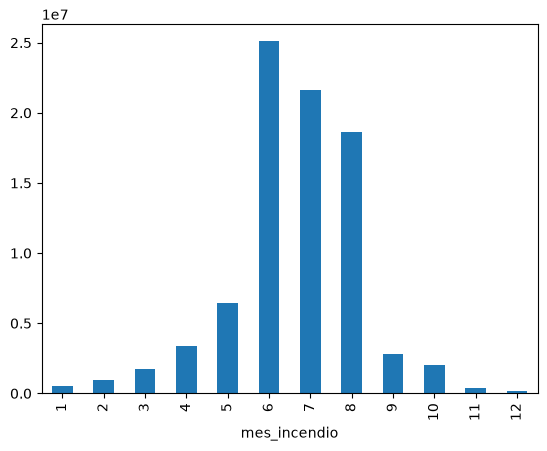

In [27]:
# Suma de área quemada por mes
suma_area_por_mes = graf.groupby("mes_incendio")["area_quemada"].sum()
suma_area_por_mes.plot(kind="bar")

fig = px.bar(x=suma_area_por_mes.index, y=suma_area_por_mes.values, labels={"x": "Mes del año", "y": "Suma de área quemada"})
fig.show()

Hipotesisi: áreas mayores en meses intermedios del año.

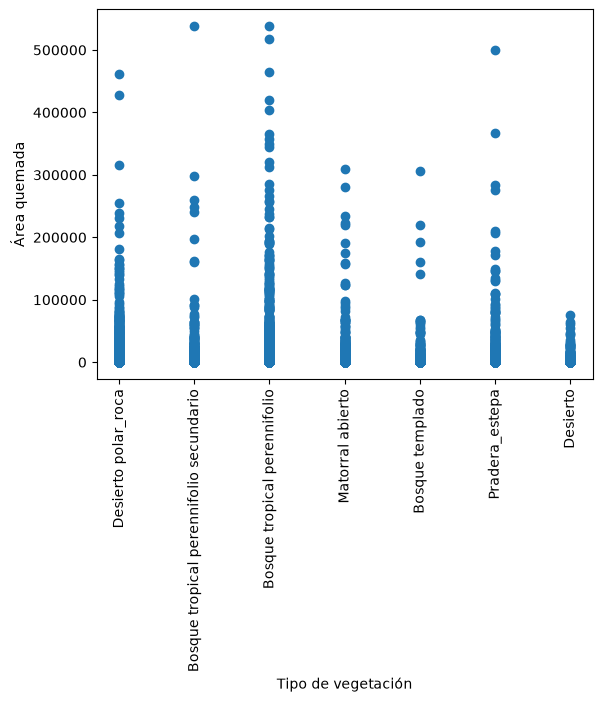

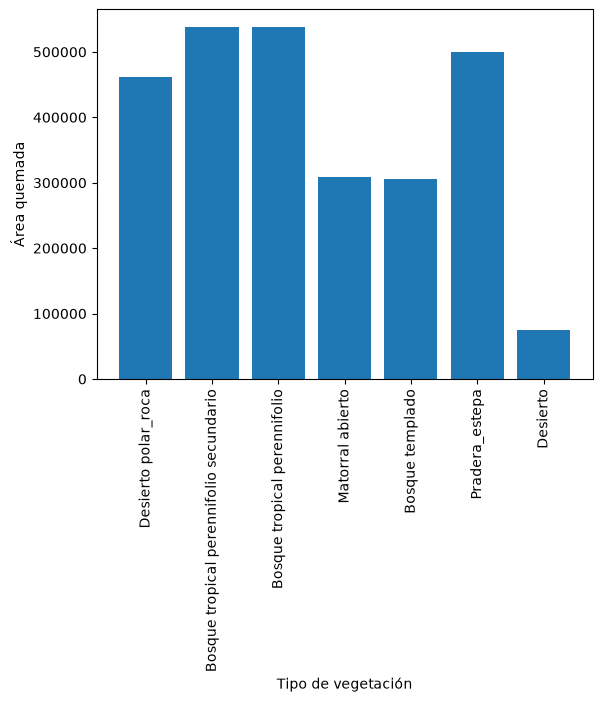

In [32]:
# Grafico: X vegetación
# Y variable de salida area_area_quemada
graf = data.copy()

plt.scatter(graf["vegetacion"], graf["area_quemada"])
plt.xticks(rotation=90)
plt.xlabel("Tipo de vegetación")
plt.ylabel("Área quemada")
plt.show()



# 2) Preparación de los datos

In [20]:
# transformación de variables categoricas a numericas
data_cat = data.loc[:, ~data.columns.isin(colNum)].copy()

# codificar clase_incendio como ordinal
tipos_existentes = data_cat["clase_incendio"].unique()
regla = {tipo: abs(i-len(tipos_existentes)) for i, tipo in enumerate(tipos_existentes)}
data_cat["clase_incendio"] = data_cat["clase_incendio"].map(regla)

# codificar mes_incendio como one-hot encoding
data_cat = pd.get_dummies(data_cat, columns=["mes_incendio"])

# codificar vegetacion con one-hot encoding
data_cat = pd.get_dummies(data_cat, columns=["vegetacion"])

# unir variables numericas y categoricas transformadas
data_num = data.loc[:, data.columns.isin(colNum)].copy()
df = pd.concat([data_num, data_cat], axis=1)


In [21]:
# Particionar data para entrenamiento y test 80-20
X = df.drop("area_quemada", axis=1)
y = df["area_quemada"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3) Entrenamiento del modelo

In [22]:
# Modelo 1. Datos sin escalar
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[ 0.01, -0.35, -0.06,...,-141.5 ,-310.1 , 353.93]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](24,)","['Prec_pre_30','Prec_pre_15','Prec_pre_7',..., 'vegetacion_Desierto polar_roca','vegetacion_Matorral abierto', 'vegetacion_Pradera_estepa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.465e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)


In [23]:
# Observar la significancia de las variables para el modelo 1 (datos sin escalar)
import statsmodels.api as sm
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:           area_quemada   R-squared:                       0.178
Model:                            OLS   Adj. R-squared:                  0.177
Method:                 Least Squares   F-statistic:                     207.2
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:57:57   Log-Likelihood:            -2.3469e+05
No. Observations:               21115   AIC:                         4.694e+05
Df Residuals:                   21092   BIC:                         4.696e+05
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------

C:\Users\juan.maya\AppData\Local\Temp\ipykernel_20548\1005385515.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_sm = sm.OLS(y_train, X_train_sm).fit()


# 4) Evaluación del modelo

In [24]:
# Evaluar el modelo en el conjunto de prueba
y_pred = model.predict(X_test)

# usar MSE
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)
# Usar R^2
r2 = r2_score(y_test, y_pred)
print("R^2 Score:", r2)
# Usar MAE
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Squared Error: 264414579.0857415
R^2 Score: 0.17412741992702252
Mean Absolute Error: 4873.6715328187765


# 5) Interpretar

* R^2 de 0.17 evidencia una capacidad baja de predicción del area del incendio. Pues el espacio lineal no se acopla casi a los datos. Esto concuerda con el error cuadratico medio que nos dice que a lo sumo tendremos un error en cada predicción de un area más o menos 264'414.579 hc.

* Sin embargo, en este modelo hay ciertas variables que pueden estar más relacionadas con la target de salida: Dado los resultados P>|t| podemos concluir que: clase_incendio; mes_incendio(Todos menos Diciembre y Marzo) y en la clase de vegetación (Todas, menos - ironicamente - vegetacion_Desierto). Son significativos. 